# Dashboard de resultados — simulación de tractores

Este notebook reúne las gráficas comparativas de etapa 4 y las visualizaciones complementarias guardadas en results/. Por defecto muestra las imágenes y tablas guardadas, sin repetir simulaciones ni sobrescribir resultados. Puedes activar una reconstrucción o una corrida nueva en la configuración.

En la configuración puedes activar una corrida completa, el resumen rápido, la validación de etapa 3, el diagnóstico de bloqueo o la regeneración de las visualizaciones complementarias.

## 1. Preparar el proyecto

In [1]:
from pathlib import Path
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

start = Path.cwd().resolve()
candidates = [start, *start.parents]
REPO_ROOT = next(
    (path for path in candidates if (path / "src" / "model.py").is_file()
     and (path / "experiments" / "stage4.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "No encontré la raíz del repositorio. Abre este notebook desde la carpeta del proyecto."
    )

os.chdir(REPO_ROOT)
RESULTS_DIR = REPO_ROOT / "results" / "stage4"
EPISODES_CSV = RESULTS_DIR / "episodes.csv"
SUMMARY_CSV = RESULTS_DIR / "summary.csv"
PAIRED_CI_CSV = RESULTS_DIR / "paired_ci.csv"
print(f"Repositorio: {REPO_ROOT.name}")
print("Resultados: results/stage4")

Repositorio: Reto_Multiagentes-dashboard
Resultados: results/stage4


## 2. Configurar qué ejecutar

In [2]:
# Cambia estas opciones a True cuando quieras ejecutar esos procesos.
RUN_FULL_STAGE4_SIMULATION = False  # 120 episodios; genera un experimento nuevo.
REBUILD_STAGE4_FROM_CSV = False      # Reanaliza el CSV y actualiza tablas e informe.
RUN_PROJECT_VISUALIZATIONS = False  # Regenera evolución, mapa y distribución; requiere AgentPy.
RUN_QUICK_RUN = False               # 5 semillas por densidad; ejecuta ambas arquitecturas.
RUN_STAGE3_VALIDATION = False        # 60 escenarios de la arquitectura improved.
RUN_DEADLOCK_DIAGNOSTIC = False      # Diagnóstico puntual, por defecto densidad 10 %, semilla 4.

DIAGNOSTIC_DENSITY = 0.10
DIAGNOSTIC_SEED = 4

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "grid.alpha": 0.22,
})

## 3. Ejecutar los módulos del proyecto

In [3]:
def run_project_module(module_name, *args, output_lines=35):
    command = [sys.executable, "-m", module_name, *map(str, args)]
    print("$", " ".join(command))
    result = subprocess.run(
        command,
        cwd=REPO_ROOT,
        capture_output=True,
        text=True,
        check=False,
    )
    stdout_lines = result.stdout.splitlines()
    if stdout_lines:
        print("\n".join(stdout_lines[-output_lines:]))
    if result.stderr.strip():
        stderr_lines = result.stderr.splitlines()
        print("\nSalida de error:\n" + "\n".join(stderr_lines[-10:]))
    if result.returncode != 0:
        raise subprocess.CalledProcessError(
            result.returncode, command, output=result.stdout, stderr=result.stderr
        )
    return result

if RUN_QUICK_RUN:
    for architecture in ("baseline", "improved"):
        run_project_module("experiments.quick_run", architecture)
else:
    print("quick_run omitido; activa RUN_QUICK_RUN para ejecutarlo.")

if RUN_STAGE3_VALIDATION:
    run_project_module("experiments.validate_stage3", output_lines=65)
else:
    print("Validación de etapa 3 omitida; activa RUN_STAGE3_VALIDATION para ejecutarla.")

if RUN_DEADLOCK_DIAGNOSTIC:
    run_project_module(
        "experiments.diagnose_deadlock",
        "--density", DIAGNOSTIC_DENSITY,
        "--seed", DIAGNOSTIC_SEED,
        output_lines=45,
    )
else:
    print("Diagnóstico de bloqueo omitido; activa RUN_DEADLOCK_DIAGNOSTIC para ejecutarlo.")

if RUN_PROJECT_VISUALIZATIONS:
    run_project_module("experiments.visualizaciones", output_lines=8)
else:
    print("Visualizaciones adicionales ya generadas; activa RUN_PROJECT_VISUALIZATIONS para regenerarlas.")

quick_run omitido; activa RUN_QUICK_RUN para ejecutarlo.
Validación de etapa 3 omitida; activa RUN_STAGE3_VALIDATION para ejecutarla.
Diagnóstico de bloqueo omitido; activa RUN_DEADLOCK_DIAGNOSTIC para ejecutarlo.
Visualizaciones adicionales ya generadas; activa RUN_PROJECT_VISUALIZATIONS para regenerarlas.


### Actualizar los resultados de etapa 4

Por defecto se muestran los PNG y CSV existentes sin sobrescribirlos. Activa `REBUILD_STAGE4_FROM_CSV` para regenerar las tablas e imágenes desde `episodes.csv`, o `RUN_FULL_STAGE4_SIMULATION` para ejecutar 120 episodios nuevos.

In [4]:
if RUN_FULL_STAGE4_SIMULATION:
    run_project_module("experiments.stage4", "--output", RESULTS_DIR, output_lines=12)
elif REBUILD_STAGE4_FROM_CSV:
    if not EPISODES_CSV.is_file():
        raise FileNotFoundError(f"No existe {EPISODES_CSV}.")
    run_project_module(
        "experiments.stage4",
        "--from-csv", EPISODES_CSV,
        "--output", RESULTS_DIR,
        output_lines=12,
    )
else:
    required_files = [
        EPISODES_CSV,
        SUMMARY_CSV,
        PAIRED_CI_CSV,
        RESULTS_DIR / "dashboard.png",
        RESULTS_DIR / "paired_effects.png",
    ]
    missing_files = [file for file in required_files if not file.is_file()]
    if missing_files:
        raise FileNotFoundError(
            "Faltan resultados guardados de etapa 4. Activa REBUILD_STAGE4_FROM_CSV "
            "o RUN_FULL_STAGE4_SIMULATION para generarlos."
        )
    print("Usando resultados guardados de etapa 4; no se sobrescribieron archivos.")


Usando resultados guardados de etapa 4; no se sobrescribieron archivos.


## 4. Cargar y revisar los resultados

In [5]:
episodes = pd.read_csv(EPISODES_CSV)
summary = pd.read_csv(SUMMARY_CSV)
paired_ci = pd.read_csv(PAIRED_CI_CSV)

required_columns = {
    "architecture", "density", "seed", "completo",
    "cobertura_pct", "ticks", "distancia_total", "combustible_total",
}
missing_columns = required_columns - set(episodes.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas en episodes.csv: {sorted(missing_columns)}")

raw_complete = episodes["completo"].astype(str).str.strip().str.lower()
valid_complete_values = {"true", "false", "1", "0"}
if not raw_complete.isin(valid_complete_values).all():
    raise ValueError("La columna completo contiene valores distintos de true/false o 1/0.")
episodes["completo"] = raw_complete.isin({"true", "1"})
episodes["density"] = pd.to_numeric(episodes["density"], errors="raise")
episodes["seed"] = pd.to_numeric(episodes["seed"], errors="raise").astype(int)

duplicates = episodes.duplicated(["density", "seed", "architecture"])
if duplicates.any():
    raise ValueError("Hay escenarios repetidos por densidad, semilla y arquitectura.")

print(f"{len(episodes)} episodios · {episodes['seed'].nunique()} semillas · "
      f"{episodes['density'].nunique()} densidades")
display(Markdown(
    "Los ticks de episodios incompletos quedan limitados por el tope configurado "
    "en la simulación; interpreta esos promedios junto con cobertura y completitud."
))

120 episodios · 20 semillas · 3 densidades


Los ticks de episodios incompletos quedan limitados por el tope configurado en la simulación; interpreta esos promedios junto con cobertura y completitud.

## 5. Resumen ejecutivo

In [6]:
by_architecture = episodes.groupby("architecture", as_index=True).agg(
    episodes=("seed", "count"),
    completed=("completo", "sum"),
    mean_coverage=("cobertura_pct", "mean"),
    mean_ticks=("ticks", "mean"),
)
by_architecture["completion_rate_pct"] = (
    100 * by_architecture["completed"] / by_architecture["episodes"]
)

def card(title, value, detail):
    return (
        '<div class="metric-card">'
        f'<div class="metric-title">{title}</div>'
        f'<div class="metric-value">{value}</div>'
        f'<div class="metric-detail">{detail}</div>'
        '</div>'
    )

cards = [
    card("Episodios", f"{len(episodes):,}", "filas en episodes.csv"),
    card(
        "Completitud improved",
        f"{by_architecture.loc['improved', 'completion_rate_pct']:.0f}%",
        f"{int(by_architecture.loc['improved', 'completed'])} de "
        f"{int(by_architecture.loc['improved', 'episodes'])} episodios",
    ),
    card(
        "Completitud baseline",
        f"{by_architecture.loc['baseline', 'completion_rate_pct']:.0f}%",
        f"{int(by_architecture.loc['baseline', 'completed'])} de "
        f"{int(by_architecture.loc['baseline', 'episodes'])} episodios",
    ),
    card(
        "Ticks promedio",
        f"{by_architecture.loc['baseline', 'mean_ticks']:.1f} / "
        f"{by_architecture.loc['improved', 'mean_ticks']:.1f}",
        "baseline / improved; incluye episodios incompletos",
    ),
]
display(HTML(
    '<style>'
    '.metric-grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(190px,1fr));'
    'gap:12px;margin:12px 0 20px}'
    '.metric-card{border:1px solid #d7dce2;border-radius:10px;padding:14px 16px;'
    'background:#fff;box-shadow:0 1px 4px #00000012}'
    '.metric-title{font-size:13px;color:#475569}'
    '.metric-value{font-size:25px;font-weight:700;color:#14212e;margin:5px 0}'
    '.metric-detail{font-size:12px;color:#64748b}'
    '</style><div class="metric-grid">' + ''.join(cards) + '</div>'
))

summary_view = summary[[
    "density", "architecture", "n", "completos", "tasa_completitud_pct",
    "cobertura_media", "ticks_media", "distancia_media", "combustible_medio",
]].rename(columns={
    "density": "Obstáculos",
    "architecture": "Arquitectura",
    "n": "Episodios",
    "completos": "Completados",
    "tasa_completitud_pct": "Completitud (%)",
    "cobertura_media": "Cobertura media (%)",
    "ticks_media": "Ticks medios",
    "distancia_media": "Distancia media (celdas)",
    "combustible_medio": "Combustible medio",
})
display(summary_view.style.format({
    "Obstáculos": "{:.0%}",
    "Completitud (%)": "{:.1f}",
    "Cobertura media (%)": "{:.2f}",
    "Ticks medios": "{:.1f}",
    "Distancia media (celdas)": "{:.1f}",
    "Combustible medio": "{:.2f}",
}).hide(axis="index"))

Obstáculos,Arquitectura,Episodios,Completados,Completitud (%),Cobertura media (%),Ticks medios,Distancia media (celdas),Combustible medio
0%,baseline,20,20,100.0,100.00,331.0,611.0,644.00
0%,improved,20,20,100.0,100.00,254.0,490.0,537.10
5%,baseline,20,19,95.0,99.95,435.8,569.8,625.40
5%,improved,20,20,100.0,100.00,265.6,527.0,608.37
10%,baseline,20,20,100.0,100.00,296.9,570.0,649.32
10%,improved,20,20,100.0,100.00,269.8,521.0,611.95


## 6. Resultados visuales

### Comparación por arquitectura y densidad

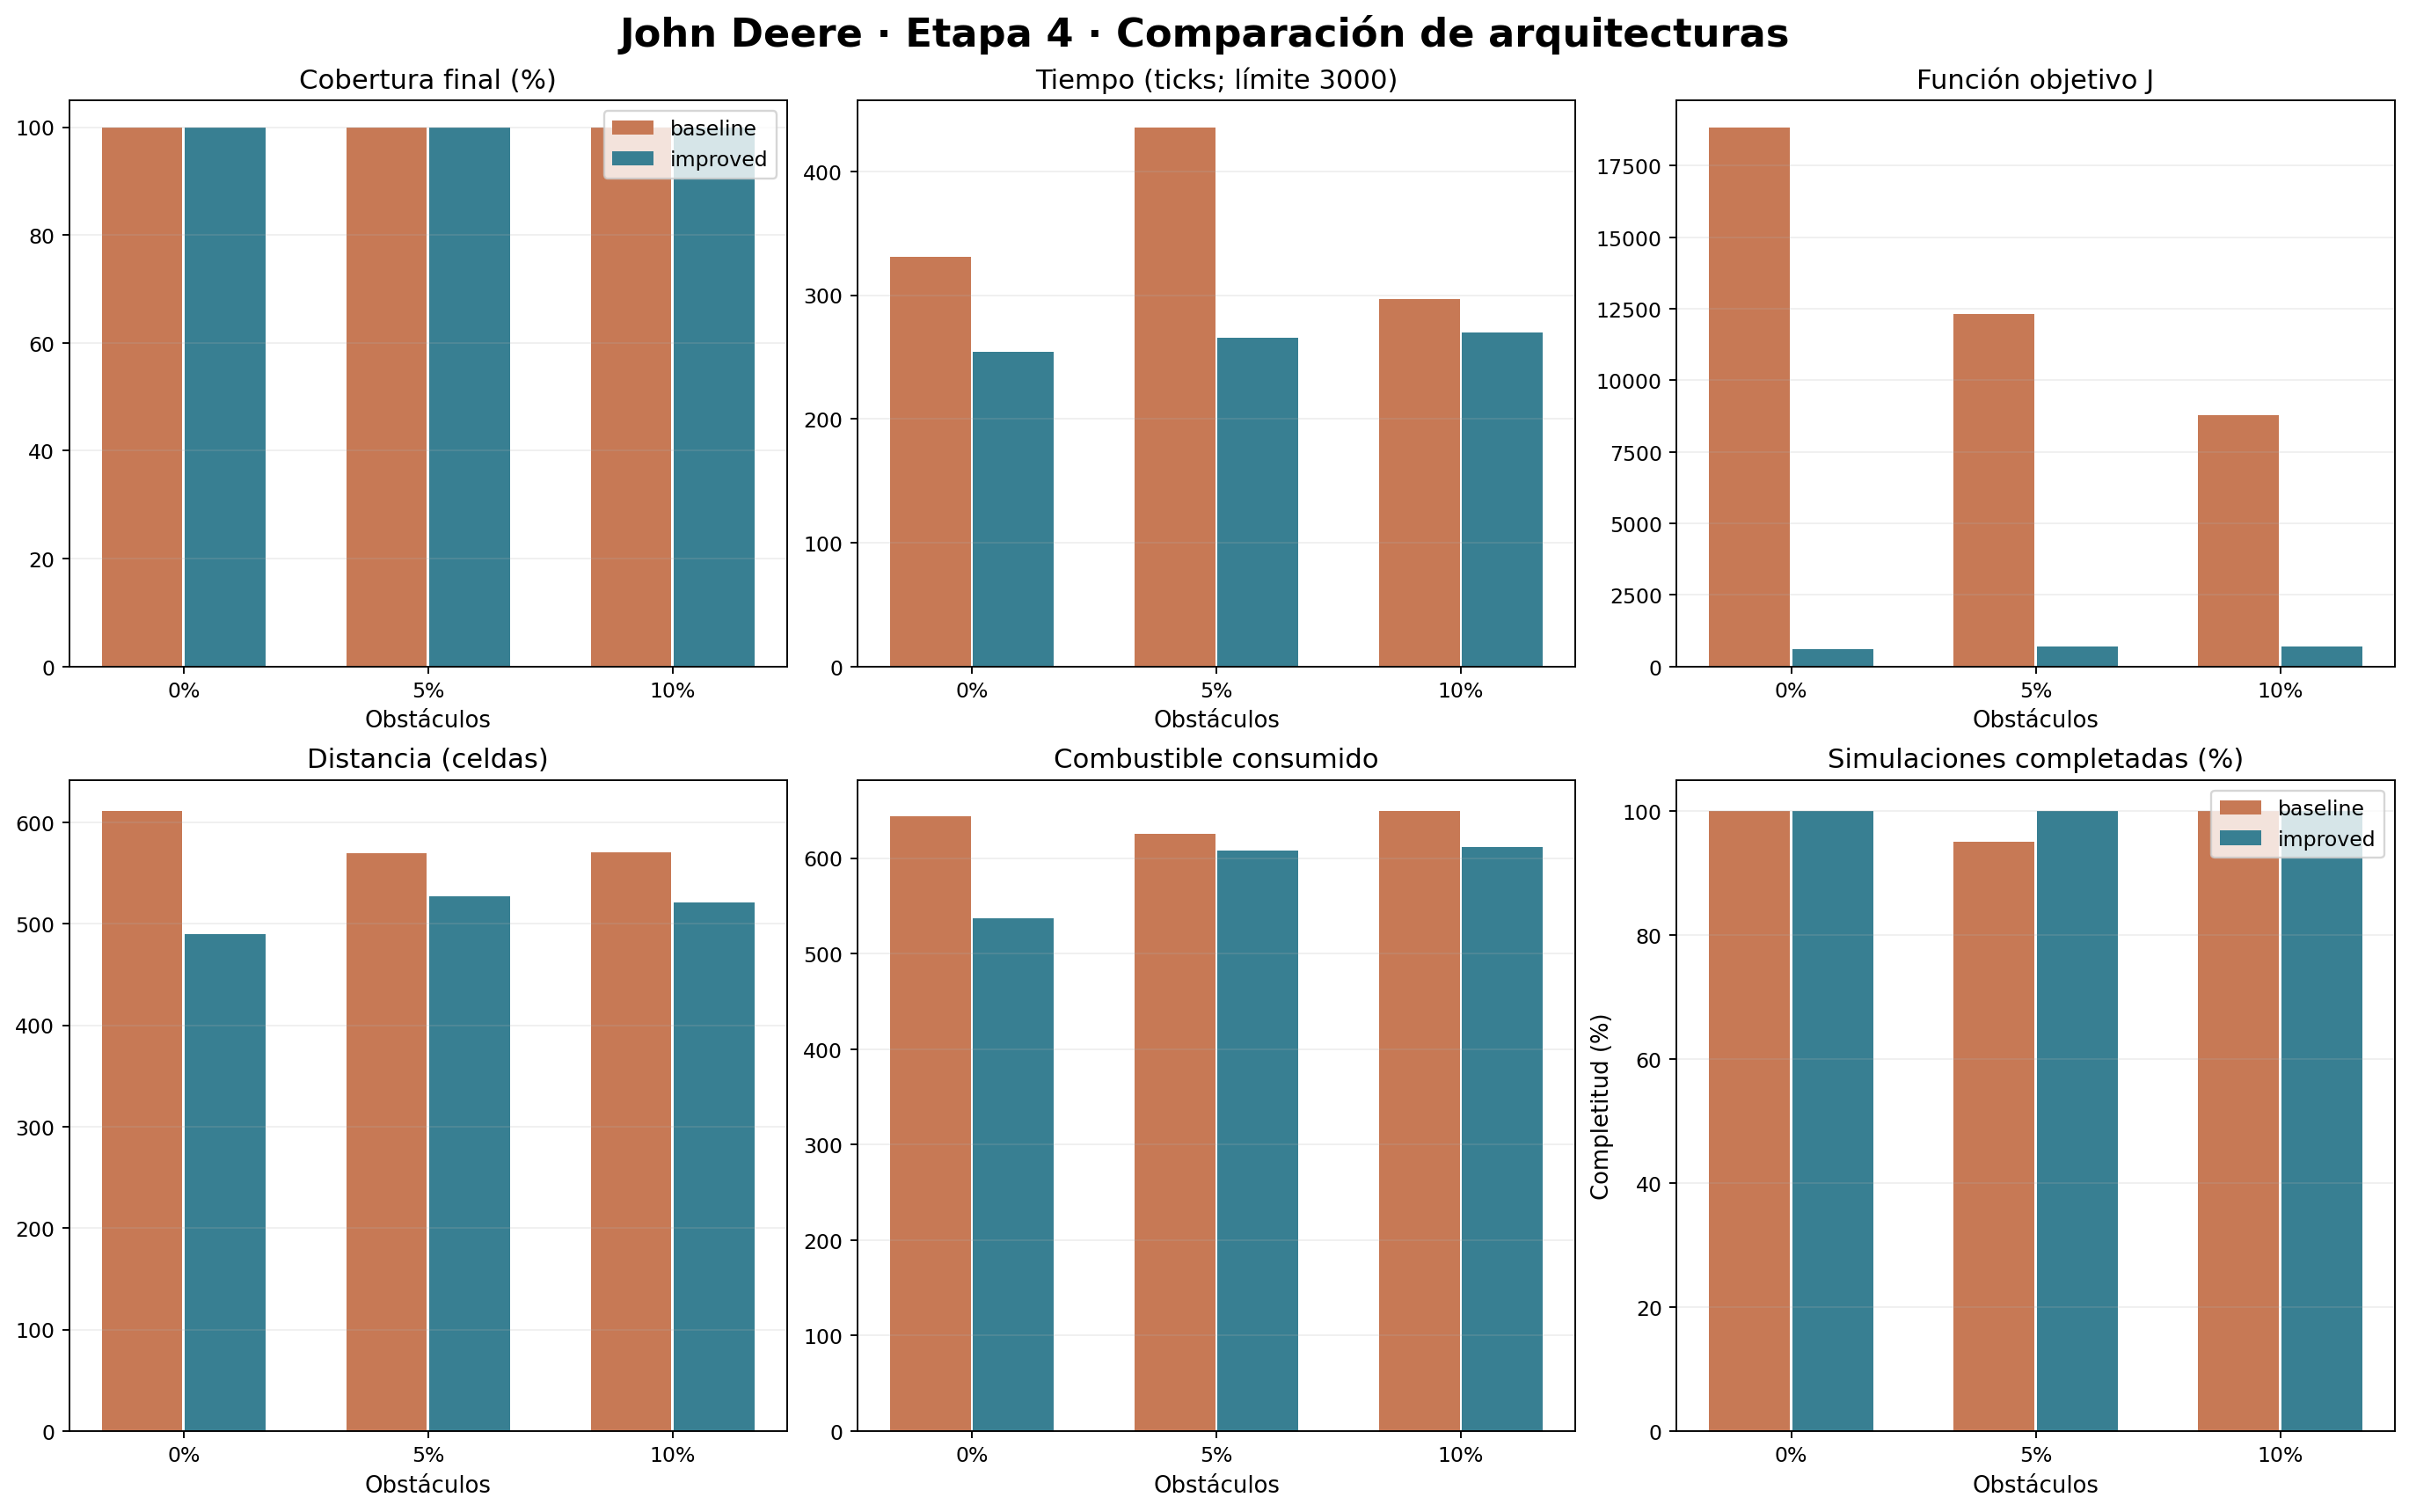

### Diferencias pareadas con IC del 95 %

En este gráfico, los valores positivos representan una mejora a favor de improved. Los intervalos son exploratorios y no corrigen comparaciones múltiples.

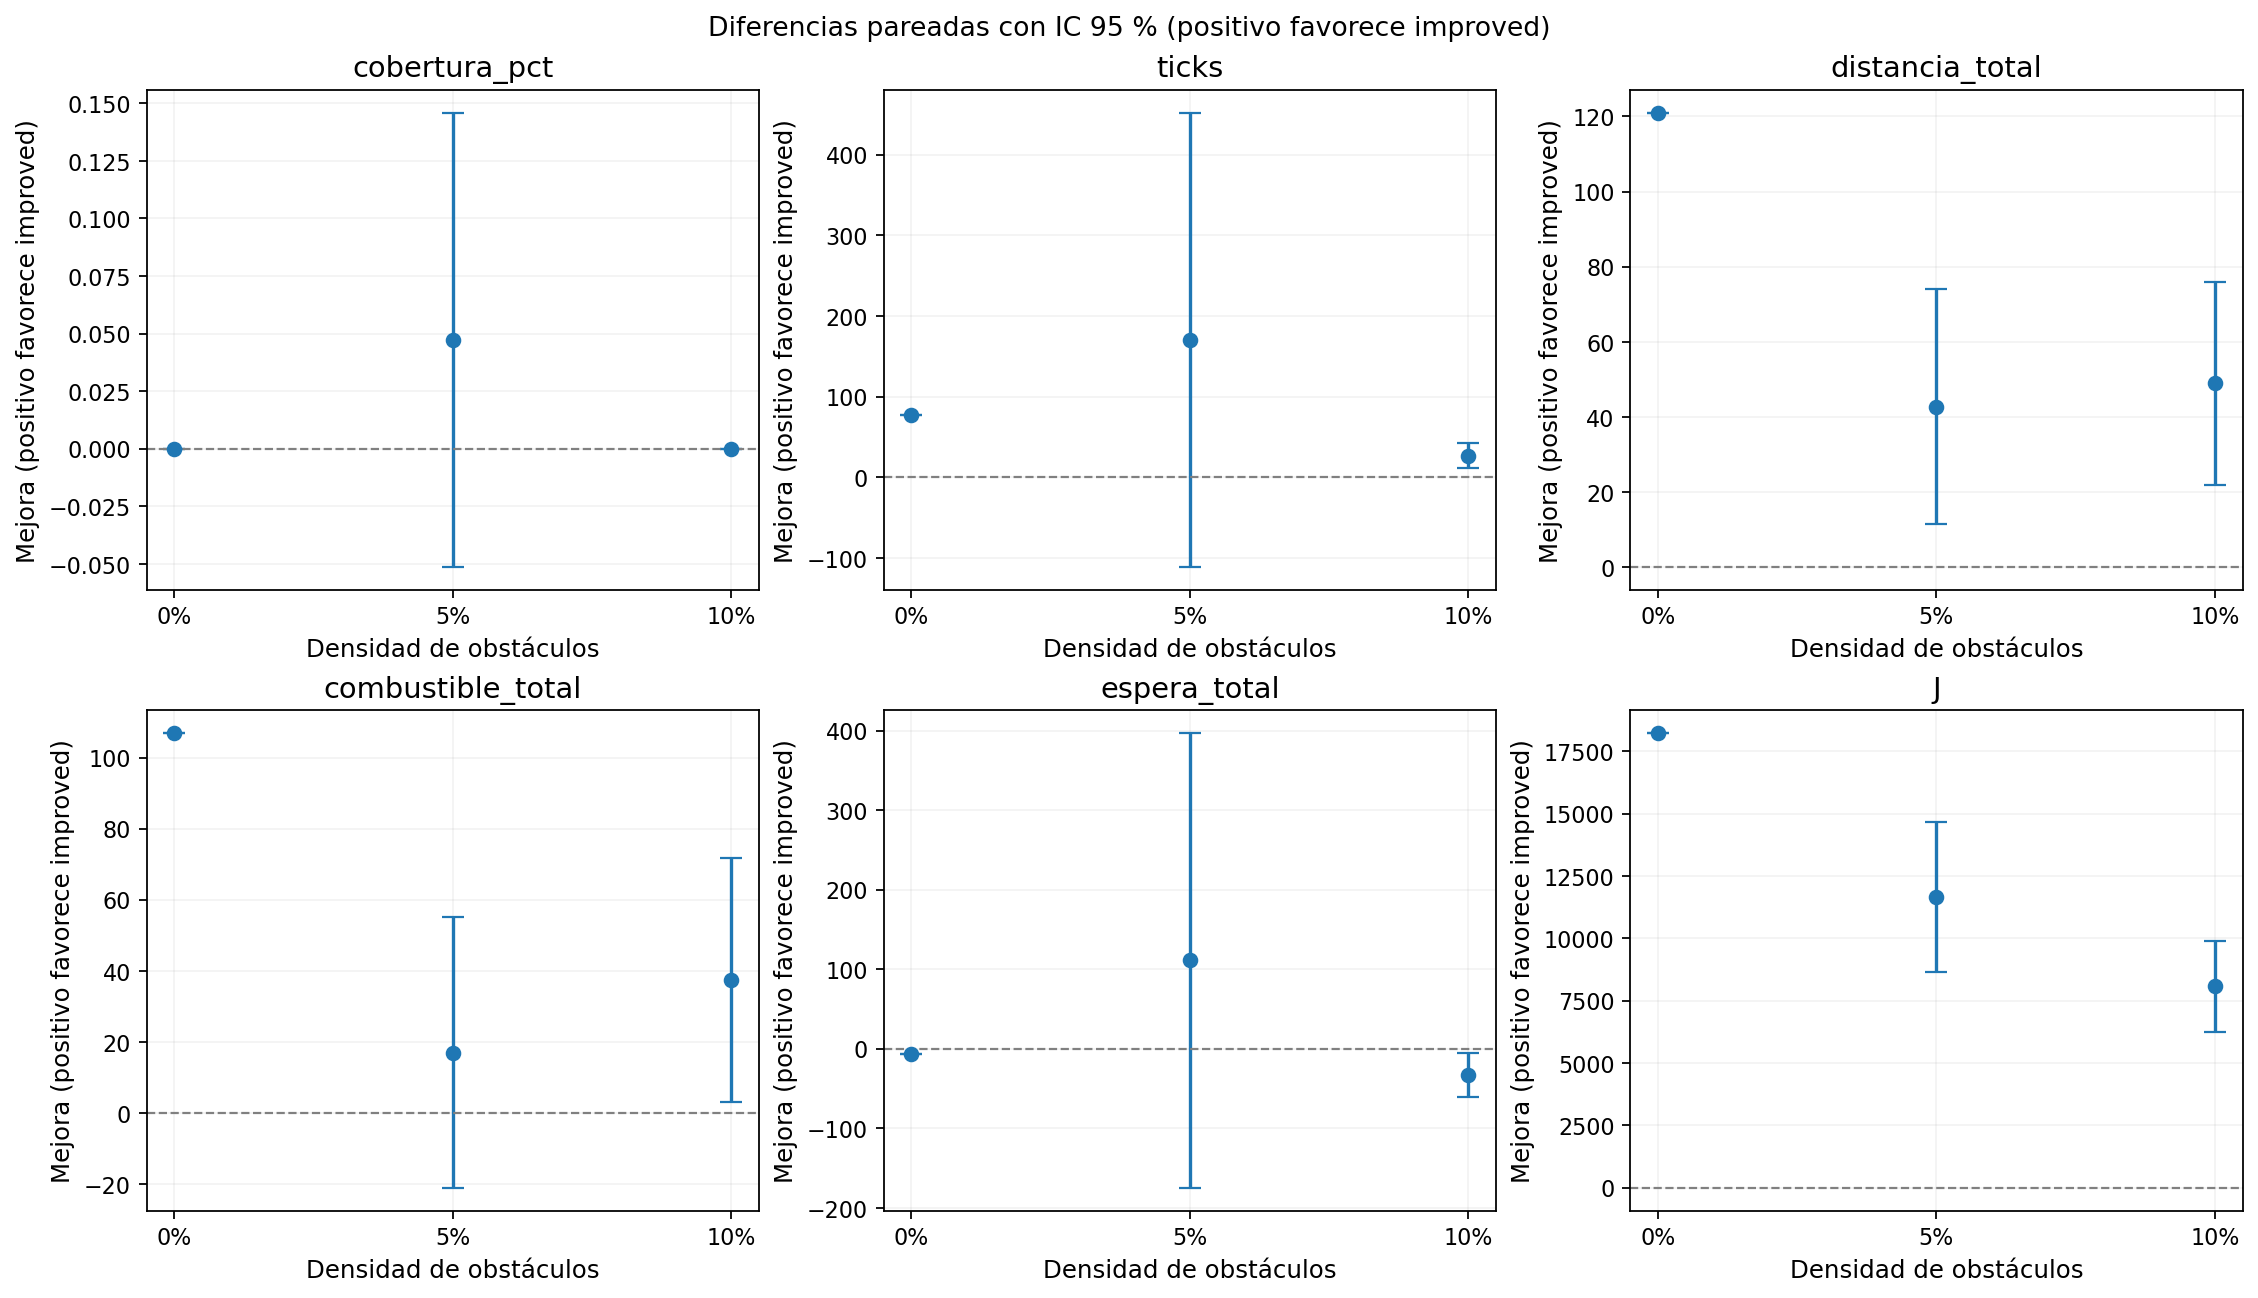

In [7]:
dashboard_image = RESULTS_DIR / "dashboard.png"
effects_image = RESULTS_DIR / "paired_effects.png"
if not dashboard_image.is_file() or not effects_image.is_file():
    raise FileNotFoundError("No encontré las imágenes generadas en results/stage4.")

display(Markdown("### Comparación por arquitectura y densidad"))
display(Image(filename=str(dashboard_image), width=1180))
display(Markdown(
    "### Diferencias pareadas con IC del 95 %\n\n"
    "En este gráfico, los valores positivos representan una mejora a favor de improved. "
    "Los intervalos son exploratorios y no corrigen comparaciones múltiples."
))
display(Image(filename=str(effects_image), width=1120))

## 7. Visualizaciones complementarias

### Evolución temporal de cobertura

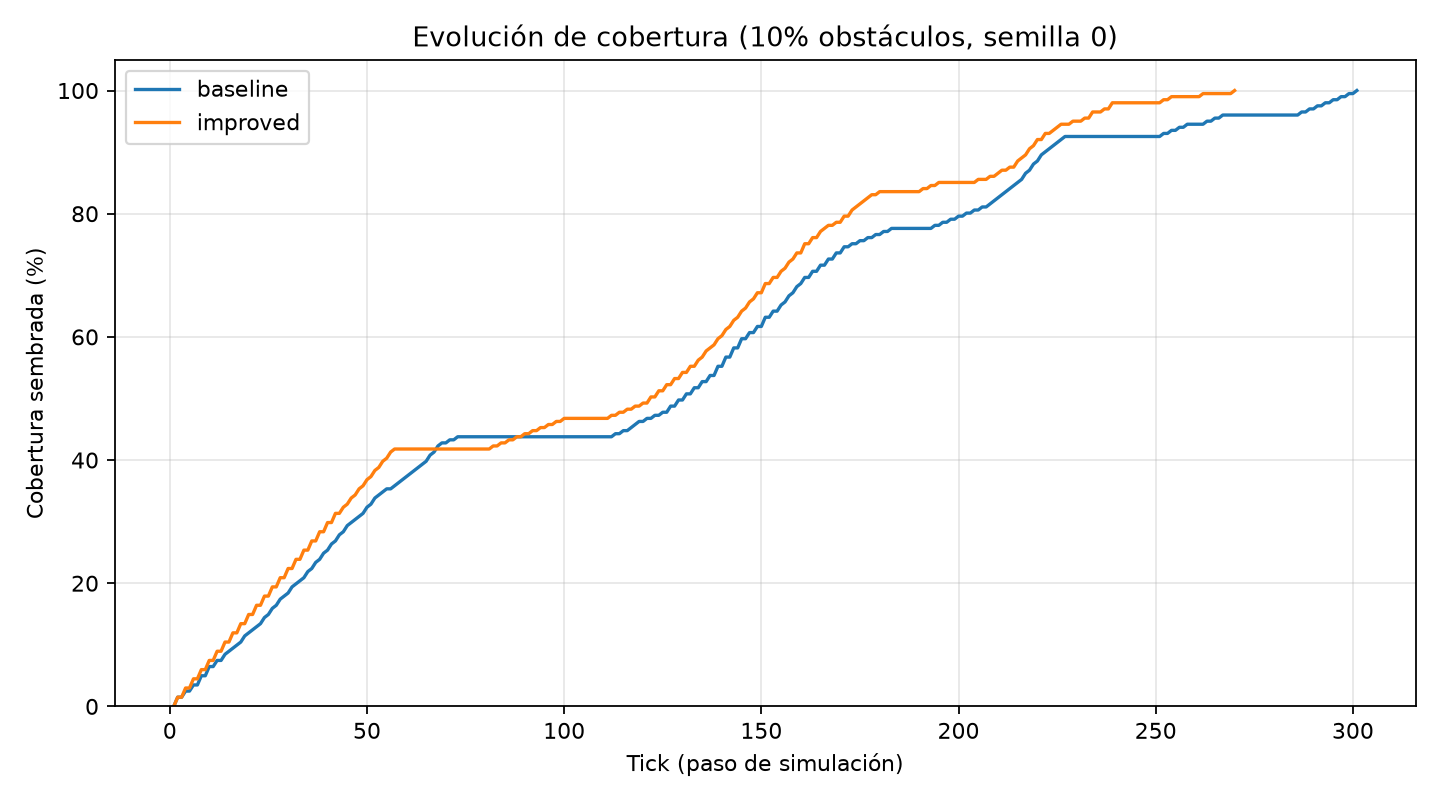

### Mapa final del campo — improved

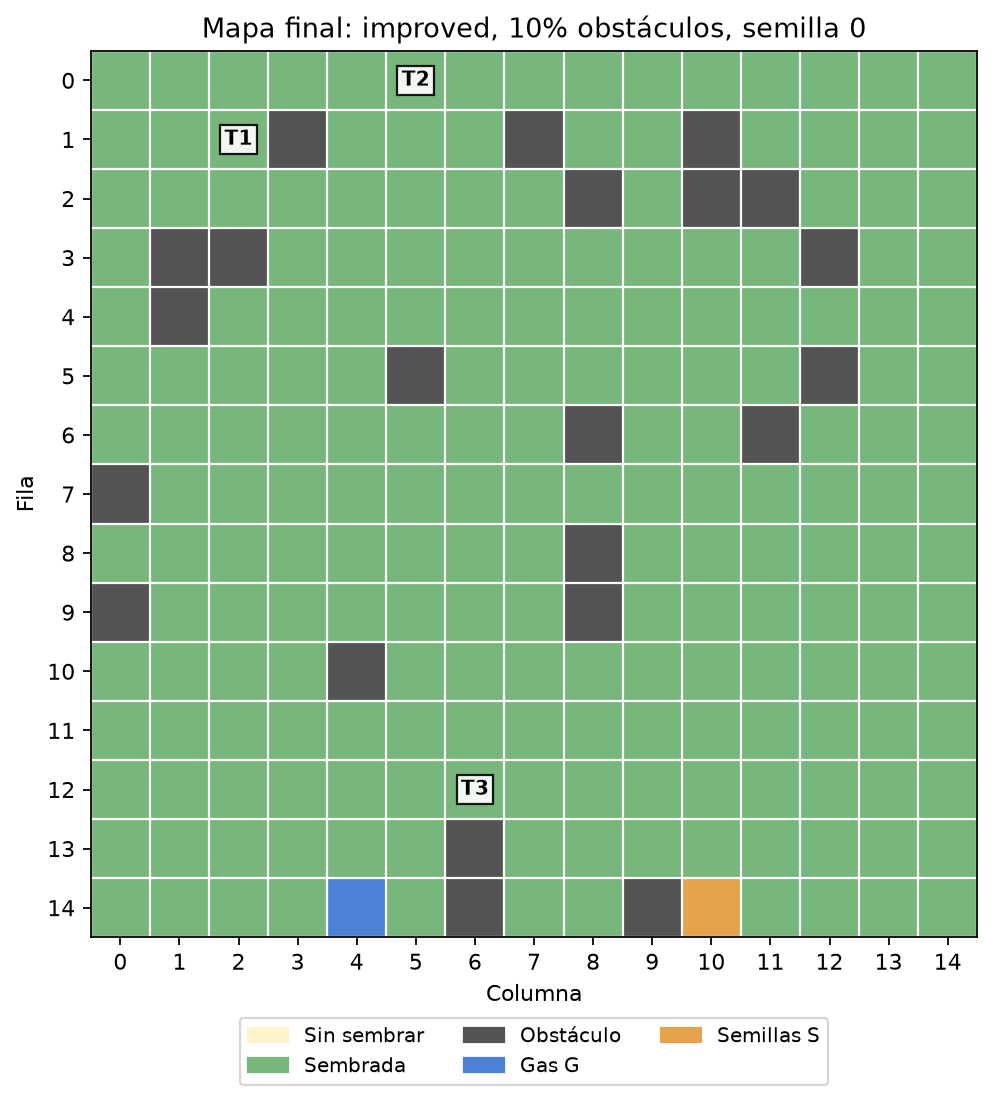

### Distribución de ticks por arquitectura y densidad

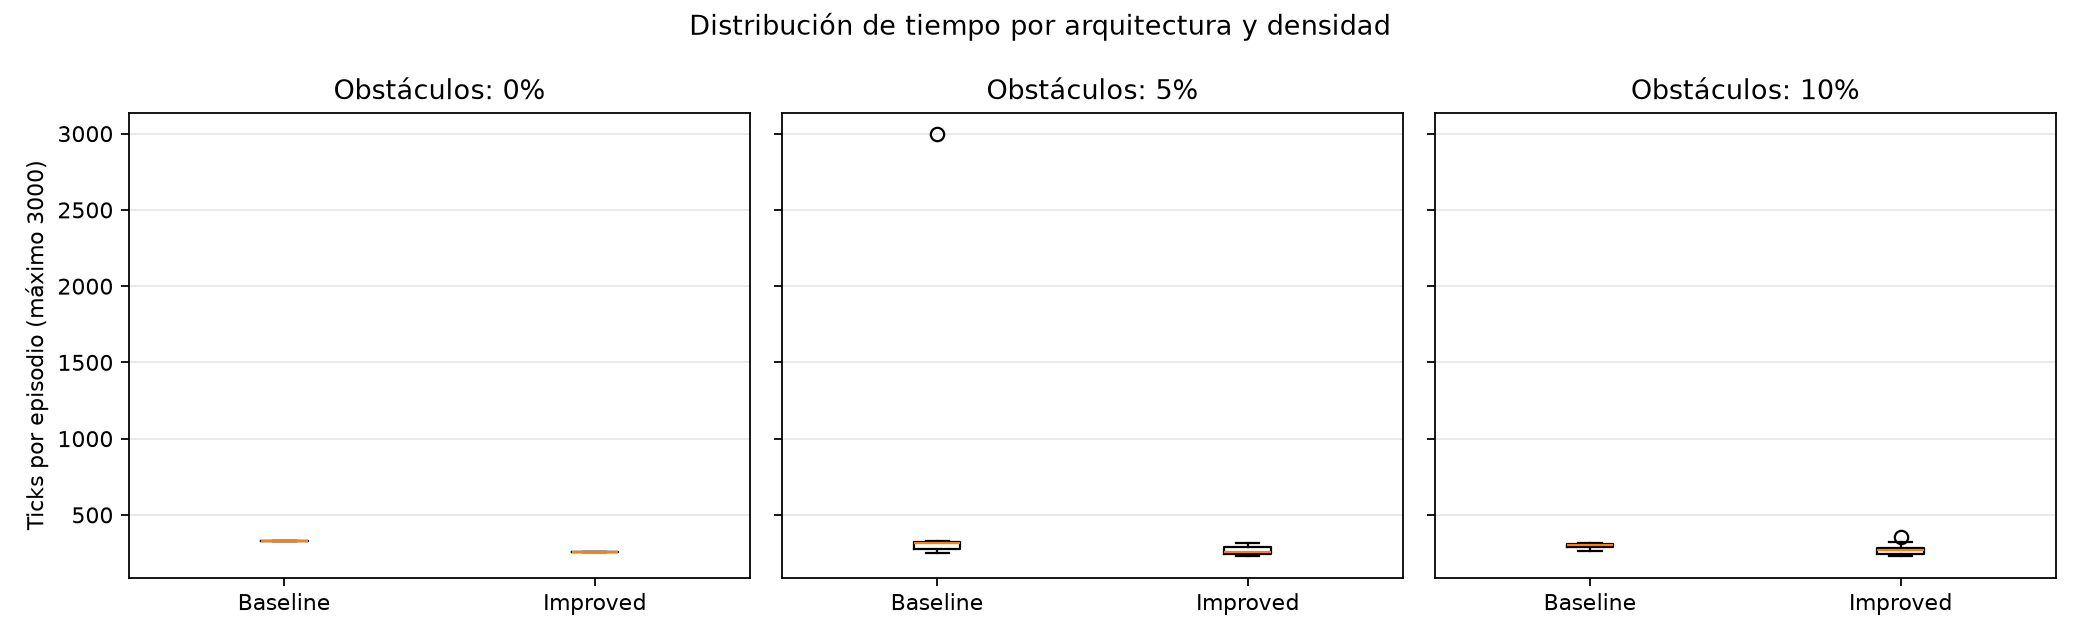

El punto en el límite de 3000 ticks corresponde a: baseline, 5%, semilla 16.

In [8]:
extra_visualizations = [
    (
        "Evolución temporal de cobertura",
        REPO_ROOT / "results" / "visualizaciones" / "evolucion_temporal.png",
        1050,
    ),
    (
        "Mapa final del campo — improved",
        REPO_ROOT / "results" / "visualizaciones" / "mapa_color.png",
        800,
    ),
    (
        "Distribución de ticks por arquitectura y densidad",
        REPO_ROOT / "results" / "visualizaciones" / "distribuciones.png",
        1050,
    ),
]
for title, image_path, width in extra_visualizations:
    if not image_path.is_file():
        raise FileNotFoundError(
            f"No existe {image_path}. Activa RUN_PROJECT_VISUALIZATIONS para generarla."
        )
    display(Markdown(f"### {title}"))
    display(Image(filename=str(image_path), width=width))
    if title == "Distribución de ticks por arquitectura y densidad":
        censored = episodes.loc[
            (~episodes["completo"]) & (episodes["ticks"] >= 3000),
            ["architecture", "density", "seed"],
        ]
        if censored.empty:
            display(Markdown("No hay episodios censurados en el límite de 3000 ticks."))
        else:
            details = ", ".join(
                f"{row.architecture}, {row.density:.0%}, semilla {row.seed}"
                for row in censored.itertuples(index=False)
            )
            display(Markdown(f"El punto en el límite de 3000 ticks corresponde a: {details}."))

## 8. Secuencia de estados y análisis de sensibilidad

La secuencia muestra un episodio de `improved` con 10 % de obstáculos y semilla 0. Los barridos de sensibilidad usan 10 semillas y también son exploratorios; complementan el experimento principal de 120 episodios y no deben leerse como una nueva comparación de 20 semillas.

Las gráficas y CSV se cargan desde `results/`; ejecutar esta sección no vuelve a simular ni modifica esos archivos.

### Recorrido del episodio improved

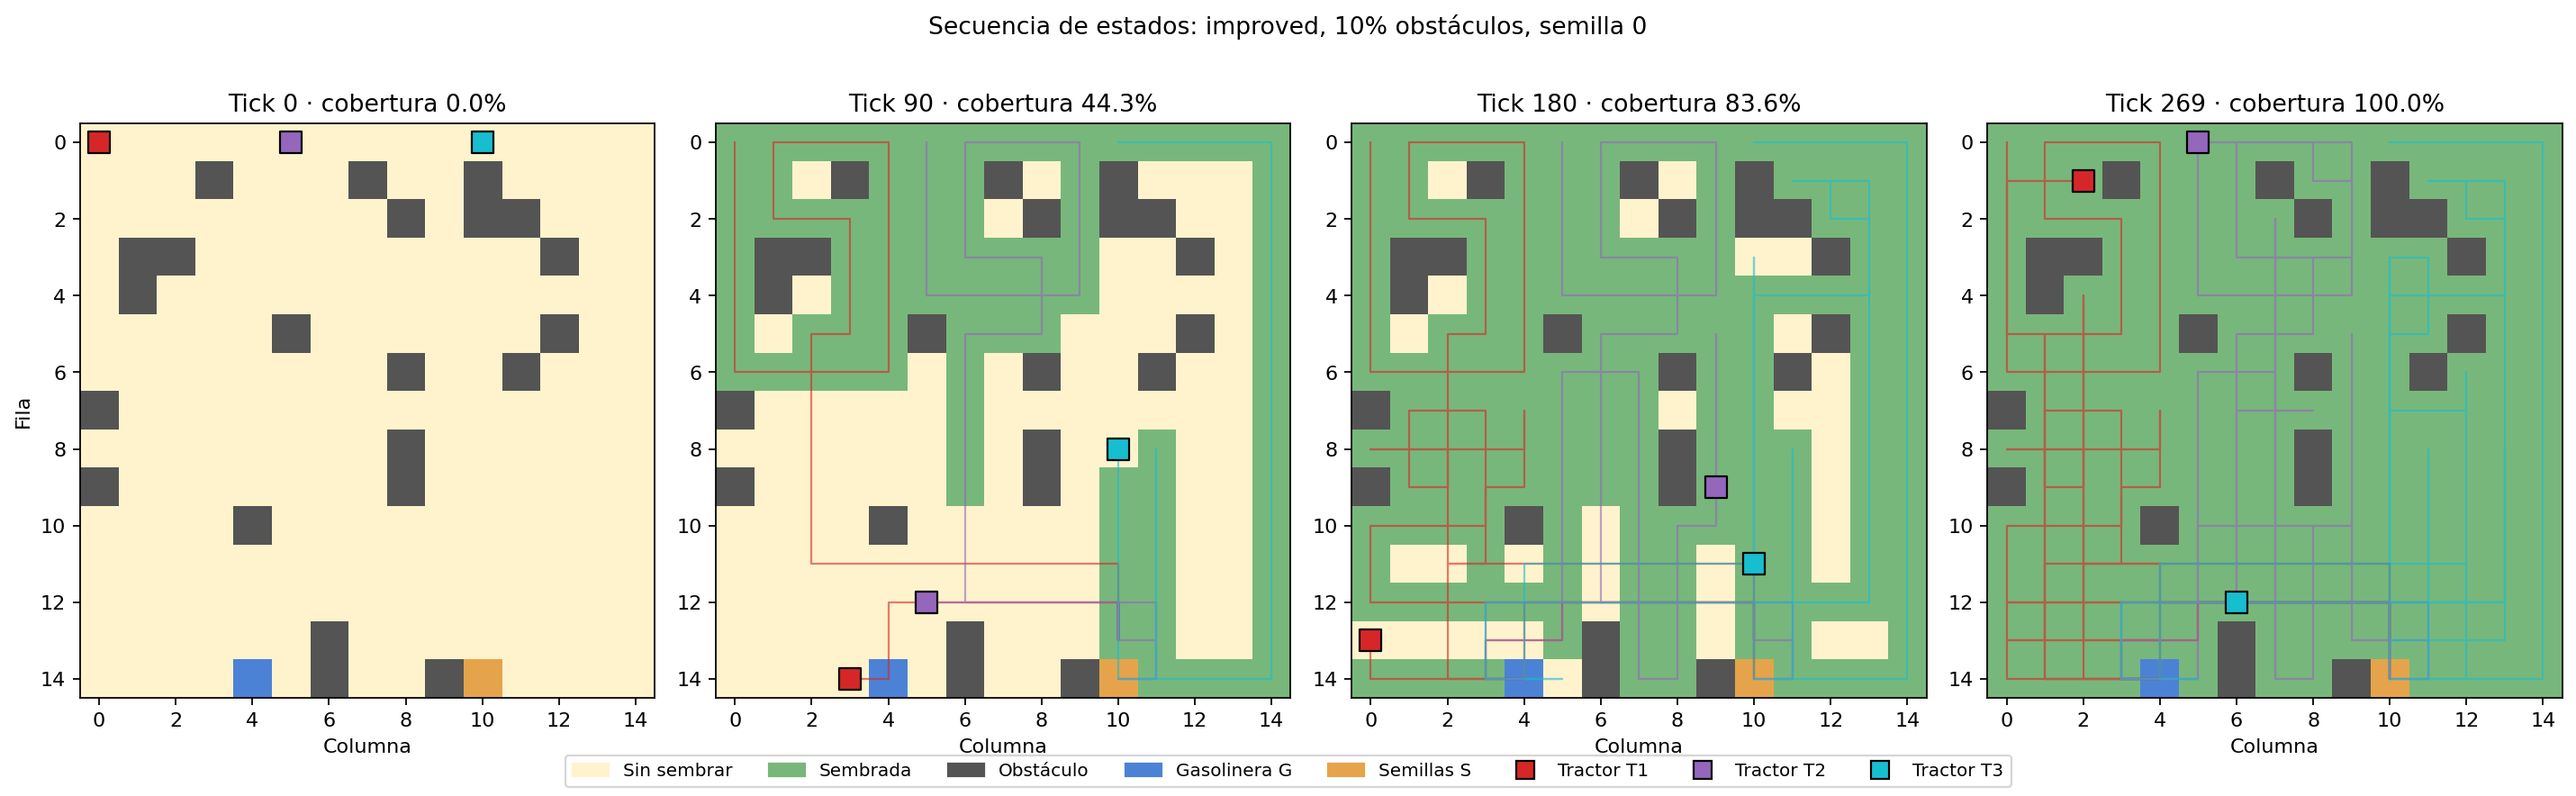

### Resumen de sensibilidad

Parámetro,Valor,Arquitectura,Episodios,Completitud (%),Ticks medios,Combustible medio
fuel_capacity,60,baseline,10,100,340.9,781.5
fuel_capacity,60,improved,10,30,2226.7,4188.6
fuel_capacity,80,baseline,10,100,295.8,660.0
fuel_capacity,80,improved,10,100,277.3,613.1
fuel_capacity,100,baseline,10,100,261.3,579.1
fuel_capacity,100,improved,10,100,314.9,648.9
fuel_capacity,120,baseline,10,100,239.5,556.8
fuel_capacity,120,improved,10,100,304.9,580.5
seed_threshold,0,improved,10,100,281.7,668.0
seed_threshold,2,improved,10,100,277.3,613.1


### Sensibilidad a capacidad de combustible

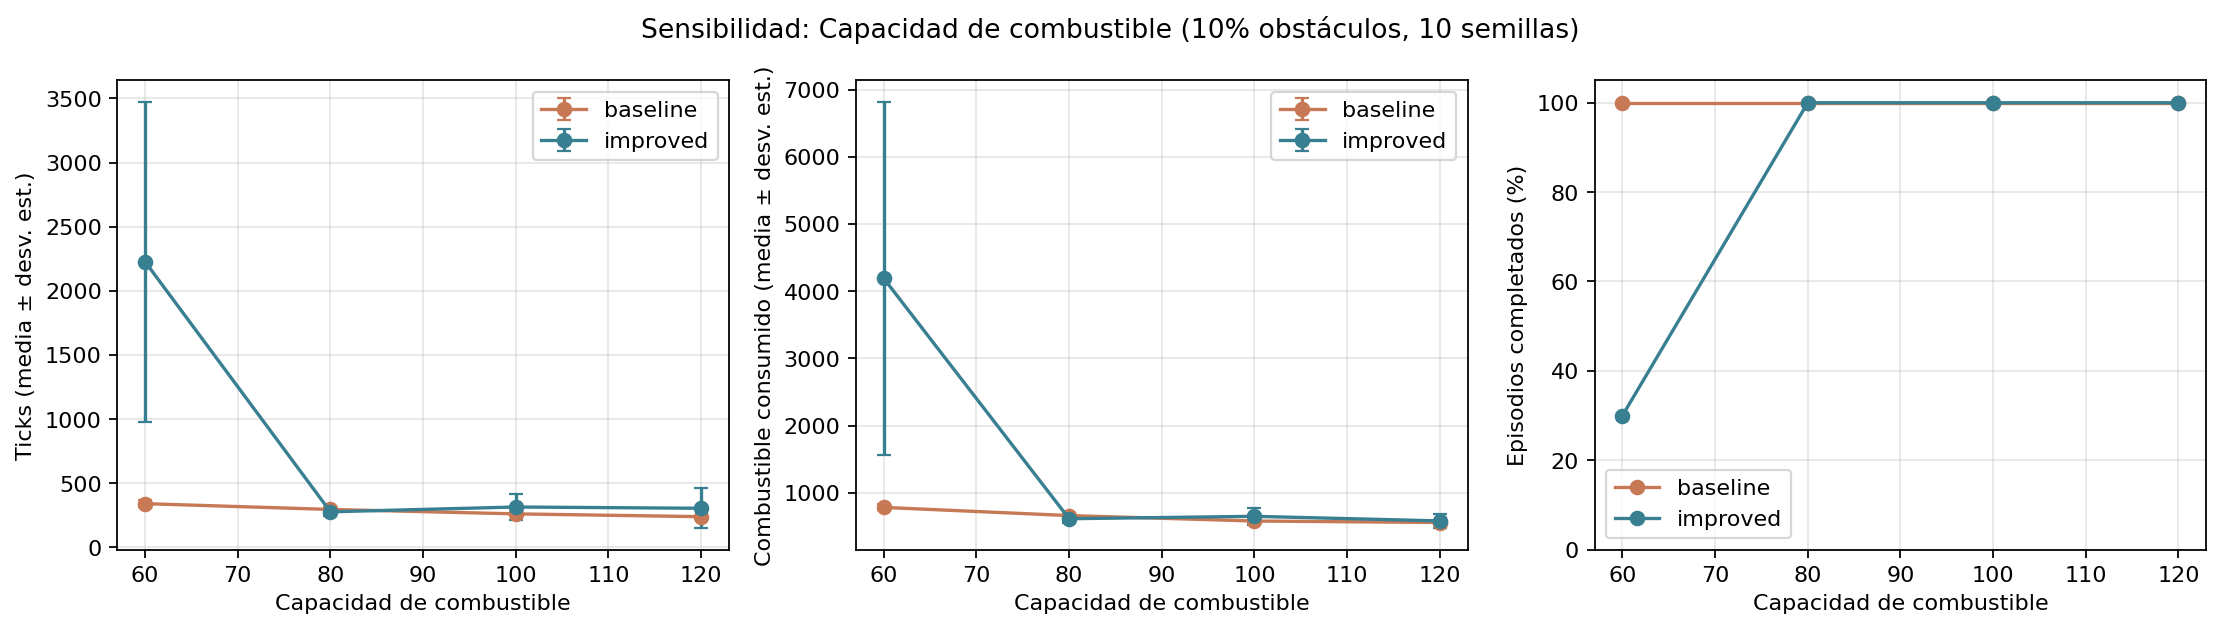

### Sensibilidad al umbral de semillas

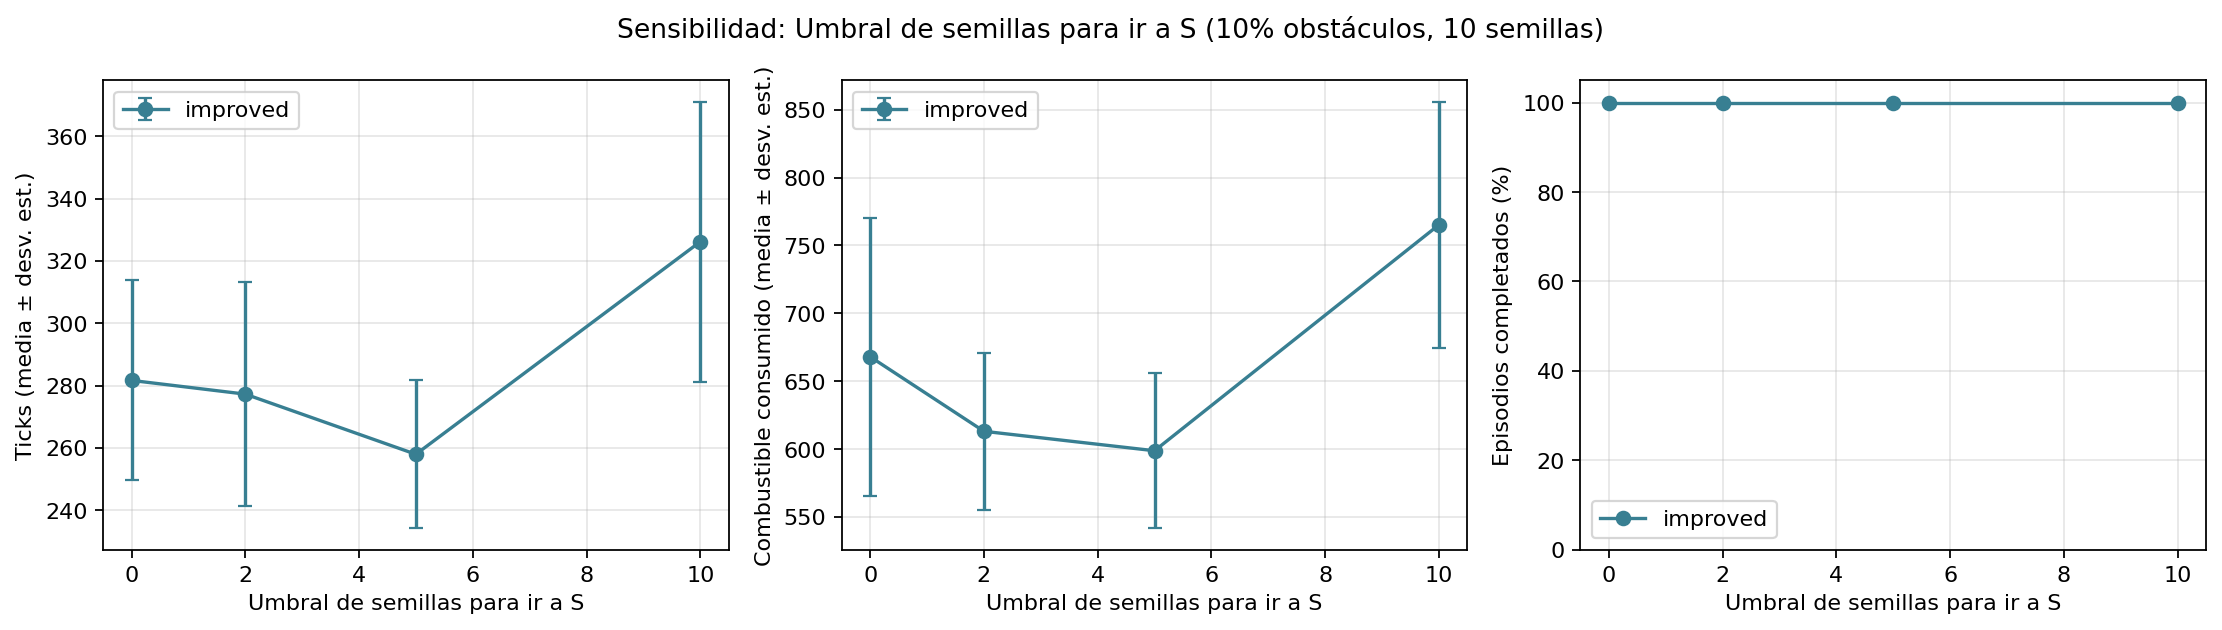

### Sensibilidad de J al peso de colisiones

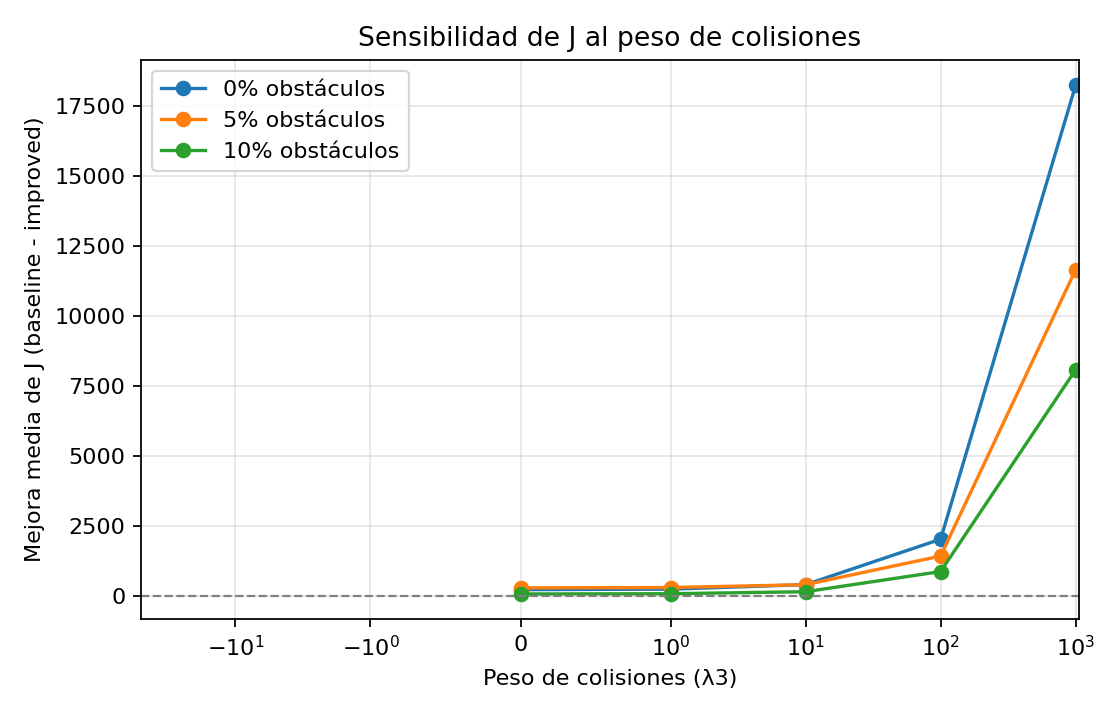

Obstáculos,Peso de colisiones (λ₃),Mejora media en J,Pares a favor de improved (%)
0%,0,225.9,100.0%
0%,1,243.9,100.0%
0%,10,405.9,100.0%
0%,100,2025.9,100.0%
0%,1000,18225.9,100.0%
5%,0,290.8,80.0%
5%,1,302.1,80.0%
5%,10,404.3,95.0%
5%,100,1425.8,100.0%
5%,1000,11640.8,100.0%


In [9]:
from IPython.display import Image, Markdown, display

state_image = REPO_ROOT / "results" / "visualizaciones" / "secuencia_estados.png"
if not state_image.is_file():
    raise FileNotFoundError(state_image)
display(Markdown("### Recorrido del episodio improved"))
display(Image(filename=str(state_image), width=1300))

sensitivity_csv = REPO_ROOT / "results" / "sensibilidad" / "sensibilidad.csv"
weights_csv = REPO_ROOT / "results" / "sensibilidad" / "sensibilidad_pesos_J.csv"
sensitivity = pd.read_csv(sensitivity_csv)
weights = pd.read_csv(weights_csv)

sensitivity_summary = (
    sensitivity.groupby(["parametro", "valor", "arquitectura"], as_index=False)
    .agg(
        episodios=("seed", "count"),
        completitud_pct=("completo", lambda values: 100 * values.mean()),
        ticks_medio=("ticks", "mean"),
        combustible_medio=("combustible_total", "mean"),
    )
    .rename(columns={
        "parametro": "Parámetro",
        "valor": "Valor",
        "arquitectura": "Arquitectura",
        "episodios": "Episodios",
        "completitud_pct": "Completitud (%)",
        "ticks_medio": "Ticks medios",
        "combustible_medio": "Combustible medio",
    })
)
display(Markdown("### Resumen de sensibilidad"))
display(sensitivity_summary.style.format({
    "Valor": "{:g}",
    "Completitud (%)": "{:.0f}",
    "Ticks medios": "{:.1f}",
    "Combustible medio": "{:.1f}",
}).hide(axis="index"))

display(Markdown("### Sensibilidad a capacidad de combustible"))
display(Image(filename=str(REPO_ROOT / "results" / "sensibilidad" / "sensibilidad_fuel_capacity.png"), width=1100))
display(Markdown("### Sensibilidad al umbral de semillas"))
display(Image(filename=str(REPO_ROOT / "results" / "sensibilidad" / "sensibilidad_seed_threshold.png"), width=1100))
display(Markdown("### Sensibilidad de J al peso de colisiones"))
display(Image(filename=str(REPO_ROOT / "results" / "sensibilidad" / "sensibilidad_pesos_J.png"), width=1000))

weights_view = weights.rename(columns={
    "density": "Obstáculos",
    "lambda3": "Peso de colisiones (λ₃)",
    "mejora_media_J": "Mejora media en J",
    "pct_pares_improved_mejor": "Pares a favor de improved (%)",
})
display(weights_view.style.format({
    "Obstáculos": "{:.0%}",
    "Peso de colisiones (λ₃)": "{:g}",
    "Mejora media en J": "{:.1f}",
    "Pares a favor de improved (%)": "{:.1f}%",
}).hide(axis="index"))


## 9. Escenarios incompletos

In [10]:
incomplete = episodes.loc[~episodes["completo"], [
    "density", "seed", "architecture", "cobertura_pct", "ticks",
    "acciones_rechazadas", "colisiones",
]].sort_values(["density", "architecture", "seed"])
if incomplete.empty:
    display(Markdown("No hay episodios incompletos en el CSV cargado."))
else:
    display(Markdown("Estos episodios alcanzaron el límite de simulación sin completar la siembra."))
    display(incomplete.rename(columns={
        "density": "Obstáculos",
        "seed": "Semilla",
        "architecture": "Arquitectura",
        "cobertura_pct": "Cobertura (%)",
        "ticks": "Ticks",
        "acciones_rechazadas": "Acciones rechazadas",
        "colisiones": "Colisiones",
    }).style.format({"Obstáculos": "{:.0%}", "Cobertura (%)": "{:.2f}"}).hide(axis="index"))

Estos episodios alcanzaron el límite de simulación sin completar la siembra.

Obstáculos,Semilla,Arquitectura,Cobertura (%),Ticks,Acciones rechazadas,Colisiones
5%,16,baseline,99.06,3000,2709,18


## 10. Informe estadístico

In [11]:
report_path = RESULTS_DIR / "REPORT.md"
if report_path.is_file():
    display(Markdown(report_path.read_text(encoding="utf-8")))
else:
    print("No se encontró REPORT.md en results/stage4.")

# Etapa 4 — Resultados experimentales

Diseño pareado: mismas semillas y densidades para baseline e improved.
Diferencia = mejora positiva (reducción de costes o aumento de cobertura).
IC 95%: intervalo t de Student de diferencias pareadas, no ajustado por comparaciones múltiples.
**Advertencia:** los ticks están censurados en 3000 si el episodio no termina;
por tanto las comparaciones de tiempo y J pueden reflejar fallos de finalización,
no únicamente eficiencia. Interpretar cobertura y tasa de finalización primero.

## Resumen

|   density | architecture   |   n |   completos |   cobertura_media |   ticks_media |   distancia_media |   combustible_medio |   esperas_medias |   colisiones_medias |   J_medio |   tasa_completitud_pct |
|----------:|:---------------|----:|------------:|------------------:|--------------:|------------------:|--------------------:|-----------------:|--------------------:|----------:|-----------------------:|
|      0    | baseline       |  20 |          20 |           100     |        331    |            611    |             644     |             5    |               18    | 18843.8   |                    100 |
|      0    | improved       |  20 |          20 |           100     |        254    |            490    |             537.1   |            11    |                0    |   617.92  |                    100 |
|      0.05 | baseline       |  20 |          19 |            99.953 |        435.75 |            569.8  |             625.4   |           140.2  |               11.35 | 12324.9   |                     95 |
|      0.05 | improved       |  20 |          20 |           100     |        265.55 |            527    |             608.365 |            29.15 |                0    |   684.098 |                    100 |
|      0.1  | baseline       |  20 |          20 |           100     |        296.85 |            569.95 |             649.315 |             3.65 |                8    |  8775.36  |                    100 |
|      0.1  | improved       |  20 |          20 |           100     |        269.8  |            520.95 |             611.95  |            36.75 |                0    |   702.54  |                    100 |

## Diferencias pareadas e intervalos de confianza

|   density | metric              |   n |   mean_improvement |   ci95_low |   ci95_high |   p_value_exploratory |   baseline_complete |   improved_complete |
|----------:|:--------------------|----:|-------------------:|-----------:|------------:|----------------------:|--------------------:|--------------------:|
|      0    | completitud_pp      |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0    | ticks               |  20 |             77     |     77     |      77     |                 0     |                  20 |                  20 |
|      0    | cobertura_pct       |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0    | distancia_total     |  20 |            121     |    121     |     121     |                 0     |                  20 |                  20 |
|      0    | combustible_total   |  20 |            106.9   |    106.9   |     106.9   |                 0     |                  20 |                  20 |
|      0    | espera_total        |  20 |             -6     |     -6     |      -6     |                 0     |                  20 |                  20 |
|      0    | colisiones          |  20 |             18     |     18     |      18     |                 0     |                  20 |                  20 |
|      0    | acciones_rechazadas |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0    | resiembras          |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0    | desbalance          |  20 |             70     |     70     |      70     |                 0     |                  20 |                  20 |
|      0    | J                   |  20 |          18225.9   |  18225.9   |   18225.9   |                 0     |                  20 |                  20 |
|      0.05 | completitud_pp      |  20 |              5     |     -5.465 |      15.465 |                 0.33  |                  19 |                  20 |
|      0.05 | ticks               |  20 |            170.2   |   -111.544 |     451.944 |                 0.221 |                  19 |                  20 |
|      0.05 | cobertura_pct       |  20 |              0.047 |     -0.052 |       0.146 |                 0.33  |                  19 |                  20 |
|      0.05 | distancia_total     |  20 |             42.8   |     11.445 |      74.155 |                 0.01  |                  19 |                  20 |
|      0.05 | combustible_total   |  20 |             17.035 |    -21.022 |      55.092 |                 0.361 |                  19 |                  20 |
|      0.05 | espera_total        |  20 |            111.05  |   -174.741 |     396.841 |                 0.426 |                  19 |                  20 |
|      0.05 | colisiones          |  20 |             11.35  |      8.488 |      14.212 |                 0     |                  19 |                  20 |
|      0.05 | acciones_rechazadas |  20 |            135.45  |   -148.05  |     418.95  |                 0.33  |                  19 |                  20 |
|      0.05 | resiembras          |  20 |              0     |      0     |       0     |                 1     |                  19 |                  20 |
|      0.05 | desbalance          |  20 |             40.25  |     26.975 |      53.525 |                 0     |                  19 |                  20 |
|      0.05 | J                   |  20 |          11640.8   |   8637.07  |   14644.5   |                 0     |                  19 |                  20 |
|      0.1  | completitud_pp      |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0.1  | ticks               |  20 |             27.05  |     11.408 |      42.692 |                 0.002 |                  20 |                  20 |
|      0.1  | cobertura_pct       |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0.1  | distancia_total     |  20 |             49     |     21.934 |      76.066 |                 0.001 |                  20 |                  20 |
|      0.1  | combustible_total   |  20 |             37.365 |      3.025 |      71.705 |                 0.035 |                  20 |                  20 |
|      0.1  | espera_total        |  20 |            -33.1   |    -60.932 |      -5.268 |                 0.022 |                  20 |                  20 |
|      0.1  | colisiones          |  20 |              8     |      6.178 |       9.822 |                 0     |                  20 |                  20 |
|      0.1  | acciones_rechazadas |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0.1  | resiembras          |  20 |              0     |      0     |       0     |                 1     |                  20 |                  20 |
|      0.1  | desbalance          |  20 |             30.35  |     17.508 |      43.192 |                 0     |                  20 |                  20 |
|      0.1  | J                   |  20 |           8072.82  |   6247.59  |    9898.05  |                 0     |                  20 |                  20 |

## Limitaciones

- Entorno discretizado, combustible y obstáculos idealizados.
- Semillas emparejadas controlan el mapa, pero las decisiones de cada arquitectura difieren.
- Intervalos t descriptivos/exploratorios; no garantizan normalidad ni corrigen multiplicidad.
- La comparación no demuestra rendimiento en maquinaria física.
- Analizar por separado escenarios incompletos y métricas penalizadas por límite de ticks.
- El dashboard CSV muestra completitud y desempeño; no reconstruye trayectorias espaciales.
